In [1]:
import pandas as pd

**df load**

In [2]:
df = pd.read_csv("../data/raw/diabetes_binary_health_indicators_BRFSS2015.csv")
df.head(50)

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0
5,0.0,1.0,1.0,1.0,25.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,2.0,0.0,1.0,10.0,6.0,8.0
6,0.0,1.0,0.0,1.0,30.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,3.0,0.0,14.0,0.0,0.0,9.0,6.0,7.0
7,0.0,1.0,1.0,1.0,25.0,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,0.0,0.0,1.0,0.0,11.0,4.0,4.0
8,1.0,1.0,1.0,1.0,30.0,1.0,0.0,1.0,0.0,1.0,...,1.0,0.0,5.0,30.0,30.0,1.0,0.0,9.0,5.0,1.0
9,0.0,0.0,0.0,1.0,24.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,2.0,0.0,0.0,0.0,1.0,8.0,4.0,3.0


**General cleaning, info and preparation**

In [59]:
df_self.columns = df_self.columns.str.strip().str.lower()
df.columns = df.columns.str.strip().str.lower()

In [74]:
df_self = df[["diabetes_binary", "genhlth", "menthlth", "physhlth", "diffwalk"]]

In [73]:
df_self

,diabetes_binary,genhlth,menthlth,physhlth,diffwalk,highbp,highchol
0,0.0,5.0,18.0,15.0,1.0,1.0,1.0
1,0.0,3.0,0.0,0.0,0.0,0.0,0.0
2,0.0,5.0,30.0,30.0,1.0,1.0,1.0
3,0.0,2.0,0.0,0.0,0.0,1.0,0.0
4,0.0,2.0,3.0,0.0,0.0,1.0,1.0
...,...,...,...,...,...,...,...
253675,0.0,3.0,0.0,5.0,0.0,1.0,1.0
253676,1.0,4.0,0.0,0.0,1.0,1.0,1.0
253677,0.0,1.0,0.0,0.0,0.0,0.0,0.0
253678,0.0,3.0,0.0,0.0,0.0,1.0,0.0


**Linear Regression Model**

*Imports, data division and pipeline*

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing, load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report,
)

RANDOM_STATE = 42

In [120]:
target_col = "diabetes_binary"
core_features = ["genhlth", "menthlth", "physhlth", "diffwalk"]

In [121]:
X_diabetes = df[core_features]
y_diabetes = df[target_col].astype(int)

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_diabetes,
    y_diabetes,
    test_size=0.20,
    stratify=y_diabetes,
    random_state=RANDOM_STATE,
)

print("Train:", X_train_cls.shape, "Test:", X_test_cls.shape)
X_train_cls.head()

Train: (202944, 4) Test: (50736, 4)


,genhlth,menthlth,physhlth,diffwalk
153147,2.0,0.0,0.0,0.0
176137,2.0,0.0,0.0,0.0
175578,1.0,0.0,0.0,0.0
177887,4.0,0.0,0.0,0.0
182143,5.0,30.0,30.0,1.0


Manual threshold: 0.2
Accuracy: 0.7861
              precision    recall  f1-score   support

not_diabetes     0.9066    0.8378    0.8708     43667
    diabetes     0.3178    0.4668    0.3782      7069

    accuracy                         0.7861     50736
   macro avg     0.6122    0.6523    0.6245     50736
weighted avg     0.8246    0.7861    0.8022     50736



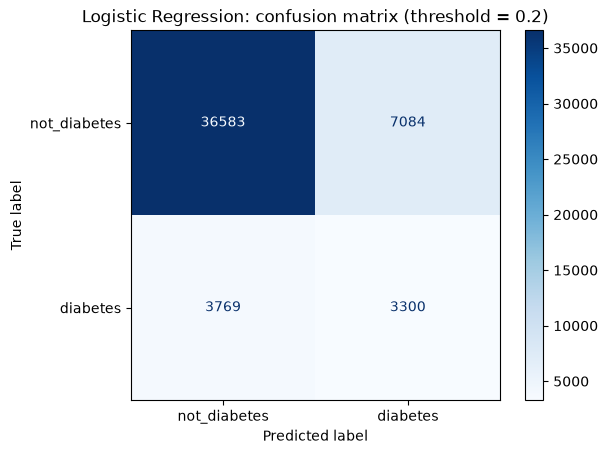

,Actual class,P(diabetes),Predicted class
0,0,0.150,0
1,1,0.244,1
2,0,0.077,0
3,0,0.077,0
4,1,0.260,1
5,0,0.037,0
6,0,0.037,0
7,0,0.036,0


In [126]:
#pipeline with manual threshold
logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
logistic_pipeline.fit(X_train_cls, y_train_cls)

y_proba_test_logistic = logistic_pipeline.predict_proba(X_test_cls)[:, 1]

threshold = 0.20 # Manual threshold
chosen_threshold = threshold
y_pred_test_manual = (y_proba_test_logistic >= chosen_threshold).astype(int)

print(f"Manual threshold: {chosen_threshold}")
print("Accuracy:", round(accuracy_score(y_test_cls, y_pred_test_manual), 4))
print(classification_report(
    y_test_cls,
    y_pred_test_manual,
    target_names=["not_diabetes", "diabetes"],
    digits=4,
))



#confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_cls,
    y_pred_test_manual,
    display_labels=["not_diabetes", "diabetes"],
    cmap="Blues",
)
plt.title(f"Logistic Regression: confusion matrix (threshold = {chosen_threshold})")
plt.show()

pd.DataFrame({
    "Actual class": y_test_cls.to_numpy()[:8],
    "P(diabetes)": y_proba_test_logistic[:8].round(3),
    "Predicted class": y_pred_test_manual[:8],
})

### In order to mitigate false negatives using only the self reported general health conditions, many false positives are created. Optimal predictions would include more clinical and demographics information

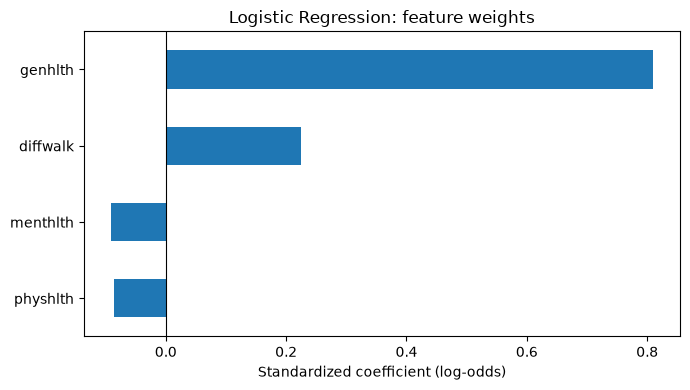

,LogReg standardized coef (log-odds)
genhlth,0.809464
diffwalk,0.225358
menthlth,-0.091342
physhlth,-0.085391


In [115]:
lr_model = logistic_pipeline.named_steps["model"]
lr_coefs = pd.Series(
    lr_model.coef_[0],
    index=X_train_cls.columns,
    name="LogReg standardized coef (log-odds)",
)
lr_coefs_sorted = lr_coefs.reindex(lr_coefs.abs().sort_values().index)

fig, ax = plt.subplots(figsize=(7, 4))
lr_coefs_sorted.plot.barh(ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(
    xlabel="Standardized coefficient (log-odds)",
    title="Logistic Regression: feature weights",
)
plt.tight_layout()
plt.show()

lr_coefs.reindex(lr_coefs.abs().sort_values(ascending=False).index).to_frame()

*General health condition is the variable with highest correlation between having or not diabetes. It can not be used individually for accurate predictions but can have a weigh on ML models*

### H0: *The distribution of self-reported general health (genhlth) is the same for individuals with diabetes and individuals without diabetes, meaning genhlth does not shift systematically between the two groups.*
### H1: *The distribution of genhlth differs between individuals with diabetes and individuals without diabetes*

In [123]:
from scipy.stats import mannwhitneyu

genhlth_diab = df.loc[df["diabetes_binary"] == 1, "genhlth"]
genhlth_nodiab = df.loc[df["diabetes_binary"] == 0, "genhlth"]

u_stat, p_val = mannwhitneyu(genhlth_diab, genhlth_nodiab, alternative="two-sided")

# Diabetes rate across each genhlth level (1 to 5)
rates_by_genhlth = df.groupby("genhlth")["diabetes_binary"].mean()

print(f"U statistic: {u_stat:.2f}, p-value: {p_val:.4e}")
print("Mean genhlth (diabetes=1 vs 0):", round(genhlth_diab.mean(), 3), "vs", round(genhlth_nodiab.mean(), 3))
print("\nDiabetes rate by genhlth:\n", rates_by_genhlth.round(4))

U statistic: 5636214826.00, p-value: 0.0000e+00
Mean genhlth (diabetes=1 vs 0): 3.291 vs 2.385

Diabetes rate by genhlth:
 genhlth
1.0    0.0252
2.0    0.0716
3.0    0.1779
4.0    0.3101
5.0    0.3789
Name: diabetes_binary, dtype: float64


**We reject H0 in favor of H1, confirming a strong statistical association where worse self-reported general health aligns with higher diabetes rates.**

### Conclusion

*Self reported general health is a strong risk signal, not a deterministic rule or sole predictor.*

**Multi-Group / Weighted Model Idea:** Combining signals across demographics, clinical conditions, lifestyle, and self-reported health & access—whether through a unified model or domain-specific sub-models/stacking whose outputs are weighted into a final score makes intuitive and practical sense for capturing distinct dimensions of risk.*